In [26]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import numpy as np
from mytools.halo_new import get_mask_sector, get_coord
from crafts_stack.halo_models import (
    get_submodel_contributions,
    get_default_model,
    apply_prior,
)
from crafts_stack.halo_fitting import halofit
from mytools.plot import plot_heatmap, plot_stack_fit_res, compare_profiles, save_plot

%matplotlib inline

# Halo contribution fitting

## stacked result

<Axes: title={'center': 'Masked stack result'}, xlabel='X', ylabel='Y'>

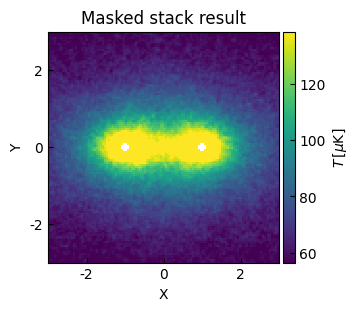

In [ ]:
stack_result = np.load("tngcube_pairstack_result.npz")["data"]

halo_peak_mask = get_mask_sector(rlim=[0.0, 0.1], thetalim=[-np.pi / 2, np.pi / 2])
stack_result_masked = np.ma.array(stack_result, mask=halo_peak_mask, fill_value=0)

plot_heatmap(stack_result_masked, title="Masked stack result", cmap="viridis")

## sector mask

<Axes: title={'center': 'Fitting mask'}, xlabel='X', ylabel='Y'>

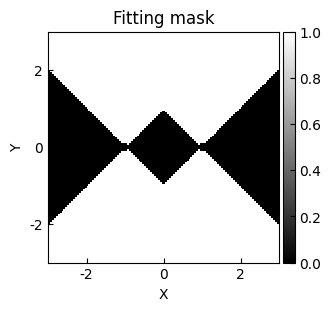

In [ ]:
fit_mask = get_mask_sector(rlim=[0.1, 5])
# fit_mask = ~get_mask_square()
plot_heatmap(fit_mask, title="Fitting mask", cmap="gray", cbar_label="")

## analytical model

In [ ]:
coord = get_coord()

model = get_default_model()

bounds = {
    "x_stddev_2": (0.1, None),
    "x_stddev_3": (0.1, None),
    "y_stddev_2": (0.1, None),
    "y_stddev_3": (0.1, None),
}
constraints = {
    # "tied": [("x_stddev_2", "x_stddev_3"), ("y_stddev_2", "y_stddev_3")],
    # "tied": [("x_stddev_2", "y_stddev_2"), ("y_stddev_3", "y_stddev_3")],
}
# model = apply_prior(model, bounds=bounds, constraints=constraints)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5)>

    [2]: <Gaussian2D(amplitude=50., x_mean=-1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [3]: <Gaussian2D(amplitude=50., x_mean=1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [4]: <Const2D(amplitude=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... y_stddev_3 theta_3 amplitude_4
    ----------- -------- -------- ----- ... ---------- ------- -----------
           50.0     -1.0      0.0   0.5 ...        0.5     0.0         0.0
Fixed parameters are: ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1', 'x_mean_2', 'y_mean_2', 'x_mean_3', 'y_mean_3']
Tied parameters are: []
Paramters bounds are: [['amplitude_0', (0.0, 100.0)], ['r_s_0', (0.1, None)], ['amplitude_1', (0.0, 100.0)], ['r_s_1', (0.1, None)], [

## analytical fitting

In [31]:
result_list, fitted_model, fit_info = halofit(
    coord, stack_result_masked, model=model, print_model=True, mask=fit_mask
)


Fitted model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=0.3630331, x_mean=-1., y_mean=0., r_s=54.95621215)>

    [1]: <NFW2D(amplitude=0.31096658, x_mean=1., y_mean=0., r_s=63.55214358)>

    [2]: <Gaussian2D(amplitude=29.35431784, x_mean=-1., y_mean=0., x_stddev=1.33194849, y_stddev=0.78016568, theta=28.22450691)>

    [3]: <Gaussian2D(amplitude=27.8458673, x_mean=1., y_mean=0., x_stddev=1.30431553, y_stddev=0.80876288, theta=-0.06610335)>

    [4]: <Const2D(amplitude=47.84099752)>
Parameters:
       amplitude_0     x_mean_0 y_mean_0 ...       theta_3           amplitude_4   
    ------------------ -------- -------- ... -------------------- -----------------
    0.3630330993104217     -1.0      0.0 ... -0.06610335194065543 47.84099751795947

Goodness of fit:
Chi-squared: 75556.429
Reduced chi-squared: 7.316
RMS residual: 2.702



Plot saved to img_tngcube_stack_fit_res_analytical.png


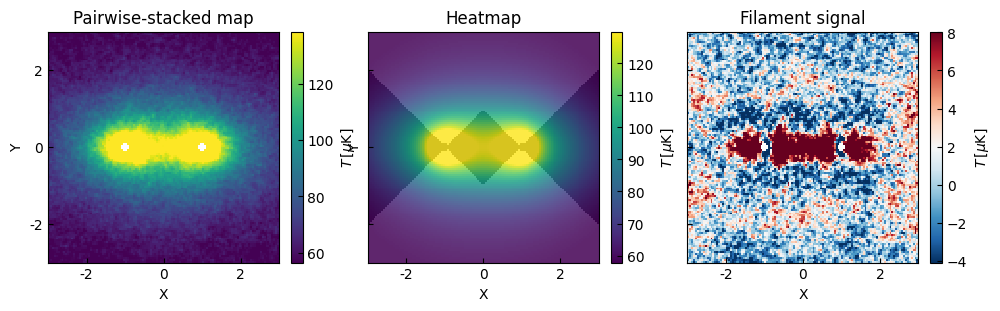

In [ ]:
axes = plot_stack_fit_res(
    result_list,  # pyright: ignore[reportArgumentType]
    norm="linear",
    cmap=["viridis", "viridis", "RdBu_r"],
    # vmax=[140,140,15],
    # vmin=[60, 60, -15],
    fit_mask=fit_mask,
)
fname = "img_tngcube_stack_fit_res_analytical.png"
save_plot(axes, fname)

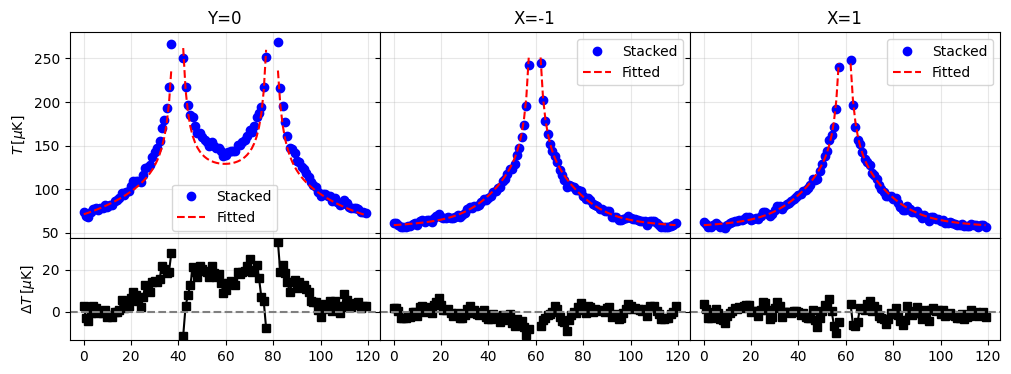

In [33]:
_, fitted, residual = result_list
fitted = np.ma.array(fitted, mask=halo_peak_mask)
compare_profiles([stack_result_masked, fitted]);

<Axes: title={'center': 'Normalized Residual'}, xlabel='X', ylabel='Y'>

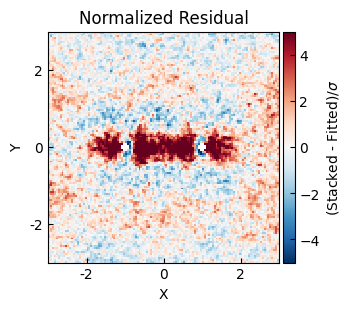

In [ ]:
plot_heatmap(
    residual / 2.5,
    title="Normalized Residual",
    cmap="RdBu_r",
    cbar_label=r"(Stacked - Fitted)/$\sigma$",
    vmax=5,
    vmin=-5,
)

In [35]:
bg_mean, bg_std = residual[fit_mask].mean(), residual[fit_mask].std()
bg_mean, bg_std

(np.float64(6.350133793307675e-05), np.float64(2.702137860166422))

## fitting error

Fitting model to original data...
Running 10 bootstrap iterations...
  Completed 1/10 iterations (1 successful)


    The maximum number of function evaluations is exceeded. [astropy.modeling.fitting]


  Completed 2/10 iterations (2 successful)
  Completed 3/10 iterations (3 successful)
  Completed 4/10 iterations (4 successful)
  Completed 5/10 iterations (5 successful)
  Completed 6/10 iterations (6 successful)
  Completed 7/10 iterations (7 successful)
  Completed 8/10 iterations (8 successful)
  Completed 9/10 iterations (9 successful)
  Completed 10/10 iterations (10 successful)

Bootstrap error map statistics:
  Min: 0.497165
  Max: 6.649151
  Median: 0.920399
  Mean: 1.040398

Parameter uncertainties from bootstrap:
  amplitude_0: 3.485706 (relative: 164.014%)
  x_mean_0: 0.000000 (relative: 0.000%)
  y_mean_0: 0.000000 (relative: nan%)
  r_s_0: 45.021135 (relative: 71.767%)
  amplitude_1: 1.927327 (relative: 164.812%)
  x_mean_1: 0.000000 (relative: 0.000%)
  y_mean_1: 0.000000 (relative: nan%)
  r_s_1: 39.466618 (relative: 70.124%)
  amplitude_2: 3.963309 (relative: 12.659%)
  x_mean_2: 0.000000 (relative: 0.000%)
  y_mean_2: 0.000000 (relative: nan%)
  x_stddev_2: 0.126676 

<string>:80: RuntimeWarning: invalid value encountered in scalar divide


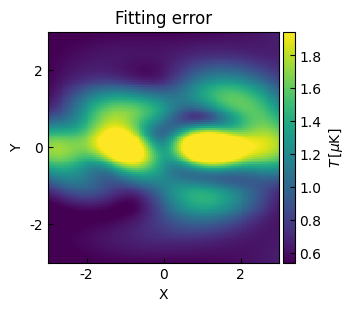

In [40]:
from crafts_stack.halo_fitting import get_fitting_error_bootstrap

error_map = get_fitting_error_bootstrap(fitted_model, *coord, stack_result_masked, n_bootstrap=10)
plot_heatmap(error_map, title="Fitting error");

array([[<Axes: title={'center': 'Y=0'}, ylabel='$T\\,[\\mu$K]'>,
        <Axes: title={'center': 'X=-1'}>,
        <Axes: title={'center': 'X=1'}>],
       [<Axes: ylabel='$\\Delta$$T\\,[\\mu$K]'>, <Axes: >, <Axes: >]],
      dtype=object)

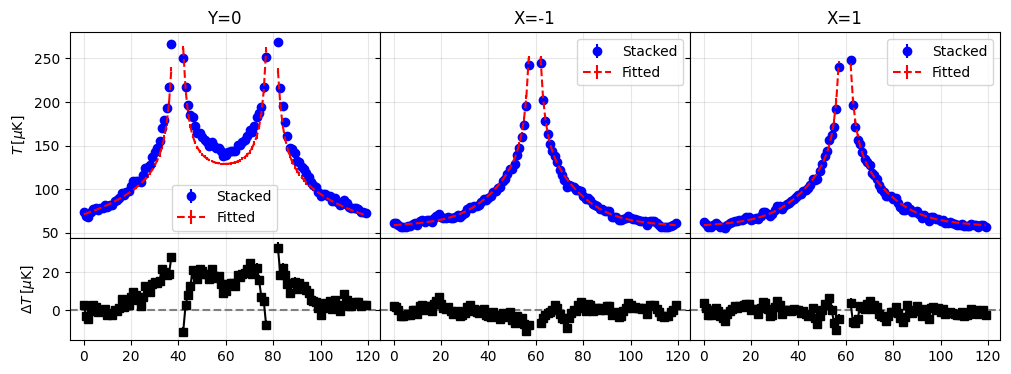

In [41]:
compare_profiles([stack_result_masked, fitted], [np.zeros_like(fitted), error_map])

# Estimate filament signal level

In [47]:
from mytools.estimate_with_error import get_signal_level
from mytools.plot import plot_profile_2c

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(17.159198614924208), np.float64(0.0), np.float64(0.208272825835158), np.float64(0.13393052281936235)]
Gauss fit covariance (without fix mean): 
[[ 2.32945705e-02 -1.67712776e-04 -1.98331019e-04]
 [-1.67712776e-04  3.83778754e-06 -5.87727398e-06]
 [-1.98331019e-04 -5.87727398e-06  3.14600369e-04]]
0 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 316.424
Reduced chi-squared: 2.704
RMS residual: 1.624

width: 0.208272825835158
width_pix: 4


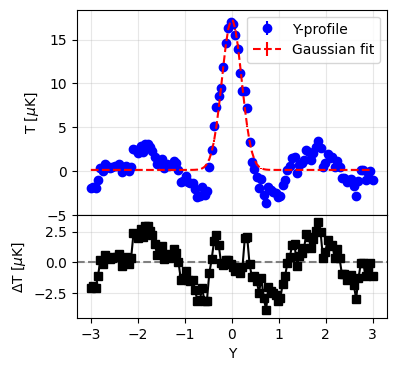

In [48]:
bounds = {
    "amplitude_0": (0, np.inf),  # amp > 0
    "stddev_0": (0, 0.6),  # sigma
}
# lx, ly, clrb, params, cov = get_signal_level(residual, bounds=bounds)
lx, ly, ly_error, clrb, clrb_err, params, cov = get_signal_level(residual, error_map, bounds=bounds)

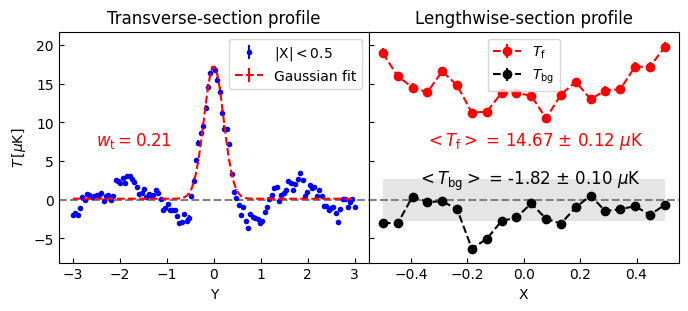

In [50]:
text_pos = [[-0.35, 7], [-0.38, 2], [-2.5, 7]]
# axes = plot_profile_2c(lx, ly, width=params[2], text_pos=text_pos)
axes = plot_profile_2c(lx, ly, width=params[2], y_err=ly_error, text_pos=text_pos)
# axes[0].set_ylim(-5, 22);
axes[1].fill_between(
    lx[-1], bg_mean + bg_std, bg_mean - bg_std, facecolor="gray", alpha=0.2
)

# Check submodel contributions

<Axes: title={'center': 'Gaussian contribution'}, xlabel='X', ylabel='Y'>

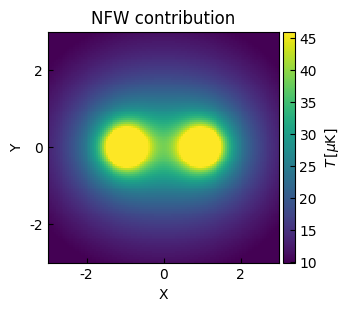

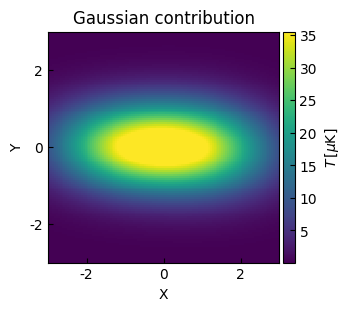

In [51]:
submodel_contris = get_submodel_contributions(fitted_model, *coord)
contris_nfw = submodel_contris[0] + submodel_contris[1]
contris_lorentz = submodel_contris[2] + submodel_contris[3]
contris_bg = submodel_contris[4]
plot_heatmap(contris_nfw, title="NFW contribution", cmap="viridis")
plot_heatmap(contris_lorentz, title="Gaussian contribution", cmap="viridis")
# plot_heatmap(submodel_contris[2], title='Gaussian left', cmap='viridis')
# plot_heatmap(submodel_contris[3], title='Gaussian right', cmap='viridis')